In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data and add cost per prompt

MODELS = ["qwen3:1.7b", "llama3.2:3b", "qwen3:4b", "qwen3:8b"]   # small → large

# Simulated price in $ per 1M tokens, scaled by model size
PRICE = {"qwen3:1.7b": 0.05, "llama3.2:3b": 0.10, "qwen3:4b": 0.15, "qwen3:8b": 0.50}

df = pd.read_csv("results/benchmark_quick.csv")   # switch to benchmark.csv later
df["cost"] = (df["prompt_tokens"] + df["output_tokens"]) * df["model"].map(PRICE) / 1e6

print(df.shape)
df.head()

(40, 13)


,qid,task,subject,model,correct,latency_s,prompt_tokens,output_tokens,answer,gold,prompt,raw_output,cost
0,gsm8k-1309,gsm8k,NaN,qwen3:1.7b,0,1.8767,113,99,1880,2280,The girls are trying to raise money for a carn...,"- Kim raises $320 more than Alexandra, who rai...",0.000011
1,gsm8k-228,gsm8k,NaN,qwen3:1.7b,1,1.9239,107,114,1,1,Kalinda is working on a 360 piece puzzle with ...,Let's calculate their combined rate:\n\n- Kali...,0.000011
2,gsm8k-51,gsm8k,NaN,qwen3:1.7b,1,1.7018,101,93,5,5,Tom's ship can travel at 10 miles per hour. H...,Tom's ship travels at 10 mph going and 6 mph r...,0.000010
3,gsm8k-563,gsm8k,NaN,qwen3:1.7b,1,1.7038,101,91,12,12,James decides to buy birthday candles for his ...,The other son is 12 - 4 = 8 years old. \nJame...,0.000010
4,gsm8k-501,gsm8k,NaN,qwen3:1.7b,1,1.6430,114,101,273,273,Mariah’s grandma was teaching her to knit. Mar...,"Mariah used $ \frac{1}{4} $ of a skein, and he...",0.000011


In [2]:
# Summary per task and model
df.groupby(["task", "model"]).agg(
    accuracy=("correct", "mean"),
    avg_latency_s=("latency_s", "mean"),
    avg_tokens=("output_tokens", "mean"),
    avg_cost=("cost", "mean"),
    n=("correct", "size"),
).round({"accuracy": 3, "avg_latency_s": 3, "avg_tokens": 2, "avg_cost": 6, "n": 1})

accuracy  avg_latency_s  avg_tokens  avg_cost  n
task  model                                                        
gsm8k llama3.2:3b       1.0          3.335       125.4  0.000023  5
      qwen3:1.7b        0.8          1.770        99.6  0.000010  5
      qwen3:4b          0.8         16.282       525.6  0.000094  5
      qwen3:8b          0.8          6.829       118.8  0.000113  5
mmlu  llama3.2:3b       0.6          2.739       108.6  0.000031  5
      qwen3:1.7b        0.4          1.173        62.6  0.000013  5
      qwen3:4b          0.4         27.341       895.2  0.000163  5
      qwen3:8b          0.8          5.330        84.0  0.000142  5

In [3]:
# Did any model leak <think> text?
# if "had_think" in df.columns:
#     print(df.groupby("model")["had_think"].mean())

# What model had answers missing
print("Models with missing answers:")
display(df[["model", "answer"]][df["answer"].isna()])

# How many answers could not be parsed at all?
print("Missing answers per model: ")
print(df["answer"].isna().groupby(df["model"]).mean())

Models with missing answers:


,model,answer
25,qwen3:4b,NaN
27,qwen3:4b,NaN
29,qwen3:4b,NaN


Missing answers per model: 
model
llama3.2:3b    0.0
qwen3:1.7b     0.0
qwen3:4b       0.3
qwen3:8b       0.0
Name: answer, dtype: float64


In [4]:
# Reshape data into wide table, with index = question id, columns = model used, value (i, j) = correctness of the model given the question
wide = df.pivot(index="qid", columns="model", values="correct")[MODELS]

# Turns each row into a string pattern -> "101" means that model_A was correct, model_B was wrong and model_C was correct
patterns = wide.astype(int).astype(str).agg("".join, axis=1)  # axis = 1 goes row by row

# Retrieve for each string pattern the number of values found
print("Pattern = correct? for", MODELS)
print(patterns.value_counts())

Pattern = correct? for ['qwen3:1.7b', 'llama3.2:3b', 'qwen3:4b', 'qwen3:8b']
1111    5
0101    2
0100    1
0000    1
1011    1
Name: count, dtype: int64


In [5]:
print(df["qid"][df["qid"] == "gsm8k-1309"].value_counts())

qid
gsm8k-1309    4
Name: count, dtype: int64


In [6]:
def evaluate(d: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for m in MODELS:
        sub = d[d["model"] == m]  # keep only the specific lines for each model
        rows.append({"policy": f"always {m}", "accuracy": sub["correct"].mean(),
                     "avg_cost": sub["cost"].mean(), "avg_latency_s": sub["latency_s"].mean()})

    # Random: picking a model uniformly = the average across models
    # Basically the metrics is the mean for all input models
    per_model = d.groupby("model")[["correct", "cost", "latency_s"]].mean()
    rows.append({"policy": "random", "accuracy": per_model["correct"].mean(),
                 "avg_cost": per_model["cost"].mean(), "avg_latency_s": per_model["latency_s"].mean()})

    # Oracle: for each question, the cheapest correct model (or cheapest overall if none is correct)
    # Sort by qid ascending, correct descending (1=correct comes first of 0=incorrect), and cost ascending(lowest cost first)
    # Remore duplicted ids => because each model solved the same questions, keep only the first that appears (cheapest and correct one)
    oracle = (d.sort_values(["qid", "correct", "cost"], ascending=[True, False, True])
                .drop_duplicates("qid"))
    rows.append({"policy": "oracle", "accuracy": oracle["correct"].mean(),
                 "avg_cost": oracle["cost"].mean(), "avg_latency_s": oracle["latency_s"].mean()})

    return pd.DataFrame(rows).round({"accuracy": 3, "avg_cost": 6, "avg_latency": 3})

results = {}
for task in df["task"].unique():
    results[task] = evaluate(df[df["task"] == task])

print("Results for GSM8K questions: ")
print(results["gsm8k"])

print("Results for MMLU questions: ")
print(results["mmlu"])

Results for GSM8K questions: 
               policy  accuracy  avg_cost  avg_latency_s
0   always qwen3:1.7b      0.80  0.000010        1.76984
1  always llama3.2:3b      1.00  0.000023        3.33540
2     always qwen3:4b      0.80  0.000094       16.28154
3     always qwen3:8b      0.80  0.000113        6.82870
4              random      0.85  0.000060        7.05387
5              oracle      1.00  0.000013        1.99684
Results for MMLU questions: 
               policy  accuracy  avg_cost  avg_latency_s
0   always qwen3:1.7b      0.40  0.000013        1.17270
1  always llama3.2:3b      0.60  0.000031        2.73884
2     always qwen3:4b      0.40  0.000163       27.34122
3     always qwen3:8b      0.80  0.000142        5.32968
4              random      0.55  0.000087        9.14561
5              oracle      0.80  0.000020        1.42164


In [7]:
oracle = (df.sort_values(["qid", "correct", "cost"], ascending=[True, False, True])
            .drop_duplicates("qid"))
oracle.groupby("task")["model"].value_counts(normalize=True).round(2)

task   model      
gsm8k  qwen3:1.7b     0.8
       llama3.2:3b    0.2
mmlu   qwen3:1.7b     0.6
       llama3.2:3b    0.4
Name: proportion, dtype: float64

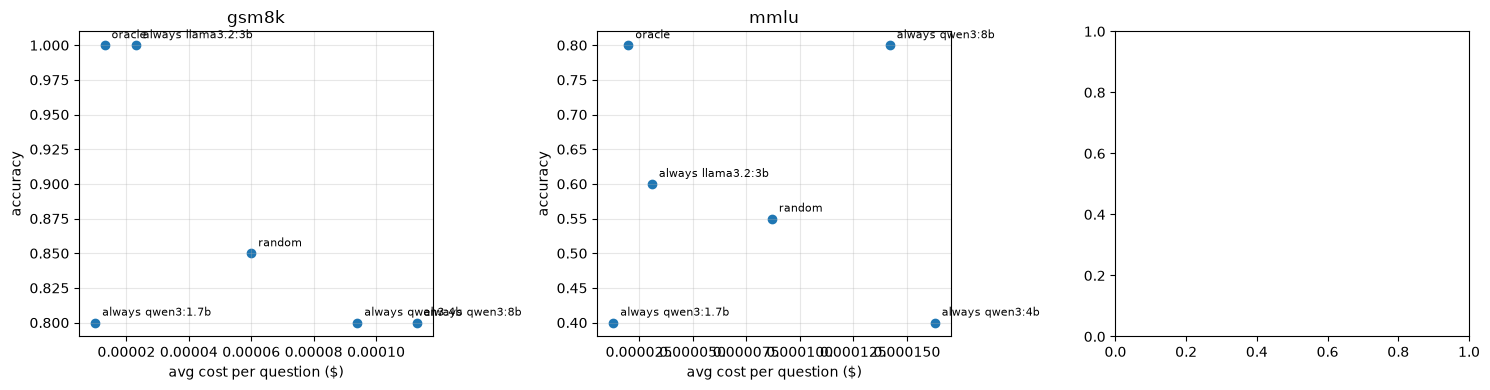

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, res) in zip(axes, results.items()):
    ax.scatter(res["avg_cost"], res["accuracy"])
    for _, r in res.iterrows():
        ax.annotate(r["policy"], (r["avg_cost"], r["accuracy"]),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.set_title(name)
    ax.set_xlabel("avg cost per question ($)")
    ax.set_ylabel("accuracy")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
# Check if models generated reasoning when solving the prompt
df["had_think"] = df["raw_output"].str.contains("<think>", na=False)
df.groupby("model")[["had_think", "output_tokens"]].mean()

,had_think,output_tokens
model,,
llama3.2:3b,0.0,117.0
qwen3:1.7b,0.0,81.1
qwen3:4b,0.0,710.4
qwen3:8b,0.0,101.4


In [10]:
# Check average output token for each model on each task

# Initially "qwen3:4b" was using to many tokens (it's more verbose into explaining the output)
# This resulted in max token usage => bad accuracy

df["chars"] = df["raw_output"].fillna("").str.len()
df["chars_per_token"] = df["chars"] / df["output_tokens"]
df.groupby(["task", "model"])[["output_tokens", "chars", "chars_per_token"]].mean().round(1)

output_tokens   chars  chars_per_token
task  model                                              
gsm8k llama3.2:3b          125.4   430.4              3.4
      qwen3:1.7b            99.6   244.2              2.4
      qwen3:4b             525.6  1495.2              2.9
      qwen3:8b             118.8   286.6              2.5
mmlu  llama3.2:3b          108.6   496.6              4.9
      qwen3:1.7b            62.6   306.4              5.0
      qwen3:4b             895.2  4133.6              4.6
      qwen3:8b              84.0   391.4              4.7

In [11]:
# Check if models hit the cap token usage for each type of question
cap = df["task"].map({"gsm8k": 1024, "mmlu": 512})
df["hit_cap"] = df["output_tokens"] >= cap
df["no_answer"] = df["answer"].isna()
df.groupby(["task", "model"])[["hit_cap", "no_answer", "correct"]].mean().round(2)

hit_cap  no_answer  correct
task  model                                   
gsm8k llama3.2:3b      0.0        0.0      1.0
      qwen3:1.7b       0.0        0.0      0.8
      qwen3:4b         0.0        0.0      0.8
      qwen3:8b         0.0        0.0      0.8
mmlu  llama3.2:3b      0.0        0.0      0.6
      qwen3:1.7b       0.0        0.0      0.4
      qwen3:4b         0.8        0.6      0.4
      qwen3:8b         0.0        0.0      0.8

In [17]:
import numpy as np, pandas as pd

X = np.load("results/embeddings.npy")
idx = pd.read_csv("results/prompt_index.csv")
print(X.shape, len(idx))          # row counts must match

# Similar prompts should have similar vectors.
sim = X @ X.T                      # cosine similarity (vectors are normalized)

not_self = ~np.eye(len(X), dtype=bool)              # True everywhere except the diagonal
same_task = tasks[:, None] == tasks[None, :]

same = sim[same_task & not_self].mean()
diff = sim[~same_task].mean()
print(f"avg similarity, same task: {same:.2f}   different task: {diff:.2f}")

(10, 384) 10
avg similarity, same task: 0.24   different task: 0.10
